## 1. Setup
Checks the GPU, mounts Google Drive and sets random seeds. All data, checkpoints and figures are stored on Drive so they survive Colab disconnects. If the raw data is missing from Colab's temporary disk, it is restored from the backup tar on Drive.

In [1]:
!nvidia-smi
!pip -q install nibabel remotezip scikit-image opencv-python-headless openpyxl

from google.colab import drive
drive.mount('/content/drive')

import os, json, random, glob
import numpy as np, matplotlib.pyplot as plt
from tqdm import tqdm

PROJECT = '/content/drive/MyDrive/mri2ct_capstone'
for sub in ['processed', 'checkpoints', 'figures']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)

random.seed(42); np.random.seed(42)
print("Project folder:", PROJECT)

Sat Oct 24 05:24:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import subprocess
ROOT = '/content/Task1/pelvis'
FILES = ['mr.nii.gz', 'ct.nii.gz', 'mask.nii.gz']
tar_path = f'{PROJECT}/raw_pelvis_48.tar'

if not os.path.exists(ROOT) and os.path.exists(tar_path):
    print("Restoring raw data from Drive backup...")
    subprocess.run(['tar', '-xf', tar_path, '-C', '/content'], check=True)
print("Raw data present:", os.path.exists(ROOT))

Restoring raw data from Drive backup...
Raw data present: True


## 2. Data download
Downloads the MRI, CT and body mask (`mr.nii.gz`, `ct.nii.gz`, `mask.nii.gz`) for the selected patients straight from the Zenodo zip, with retries and file-size checks, then verifies that every file reads to the end and saves a backup tar on Drive. Patient IDs: `1PA###` = Center A, `1PC###` = Center C. The public repository has no Center B for this task. **Skip this section if the data is already on Drive.**

In [ ]:
import os, json, time
from remotezip import RemoteZip
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

URL = "https://zenodo.org/records/7260705/files/Task1.zip?download=1"
ROOT = '/content/Task1/pelvis'
FILES = ['mr.nii.gz', 'ct.nii.gz', 'mask.nii.gz']
N_WORKERS = 4

chosen = json.load(open(f'{PROJECT}/selected_patients.json'))
chosen = sorted(chosen, key=lambda p: (p[2] != 'C'))      # Center C first
print(len(chosen), "patients | C:", sum(p[2]=='C' for p in chosen), "A:", sum(p[2]=='A' for p in chosen))

def fetch_patient(p, retries=8):
    for attempt in range(retries):
        try:
            with RemoteZip(URL) as z:
                for f in FILES:
                    name = f'Task1/pelvis/{p}/{f}'
                    dest = f'/content/{name}'
                    size = z.getinfo(name).file_size
                    if os.path.exists(dest) and os.path.getsize(dest) == size:
                        continue
                    if os.path.exists(dest):
                        os.remove(dest)
                    try:
                        z.extract(name, '/content')
                    except Exception:
                        if os.path.exists(dest): os.remove(dest)
                        raise
            return p
        except Exception:
            time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"gave up on {p}")

failed = []
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = {ex.submit(fetch_patient, p): p for p in chosen}
    for fut in tqdm(as_completed(futures), total=len(chosen), desc='Downloading'):
        try: fut.result()
        except Exception: failed.append(futures[fut])

print("Failed patients:", failed if failed else "none")

48 patients | C: 24 A: 24


Downloading: 100%|██████████| 48/48 [38:57<00:00, 48.69s/it]

Failed patients: none


In [ ]:
import os, gzip, shutil
from tqdm import tqdm

ROOT = '/content/Task1/pelvis'
FILES = ['mr.nii.gz', 'ct.nii.gz', 'mask.nii.gz']

bad = []
pats = sorted(p for p in os.listdir(ROOT) if p.startswith('1P'))
for p in tqdm(pats, desc='Verifying'):
    for f in FILES:
        path = f'{ROOT}/{p}/{f}'
        try:
            with gzip.open(path, 'rb') as g:
                shutil.copyfileobj(g, open(os.devnull, 'wb'))   # read to the very end
        except Exception:
            bad.append(path)

print(len(pats), "patients checked")
print("Corrupted or missing files:", bad if bad else "none")

Verifying: 100%|██████████| 48/48 [00:28<00:00,  1.70it/s]

48 patients checked
Corrupted or missing files: none


In [ ]:
if not os.path.exists(tar_path):
    subprocess.run(['tar', '-cf', tar_path, '-C', '/content', 'Task1/pelvis'], check=True)
print(f"Backup: {os.path.getsize(tar_path)/1e9:.2f} GB at {tar_path}")

Backup: 2.31 GB at /content/drive/MyDrive/mri2ct_capstone/raw_pelvis_48.tar


## 3. Exploring the data
The two centers use different MRI contrast (read from the spreadsheet). **Center A** (Philips Ingenia; 12 patients at 1.5 T and 12 at 3 T) has very short echo and repetition times (TE ≈ 2–5 ms, TR ≈ 4–7 ms; 7 patients have no TE recorded), consistent with the T1-weighted gradient-echo sequence described in the dataset paper. **Center C** (3 T) uses a spin-echo SPACE sequence with long times (TE 100–202 ms, TR 1500–2000 ms), i.e. T2-weighted. Three patients carry a note: hip implants (1PA025, 1PA170) and an MRI artifact (1PA144). 1PA170 is in the test set.

In [3]:
import pandas as pd
from collections import Counter
from remotezip import RemoteZip

URL = "https://zenodo.org/records/7260705/files/Task1.zip?download=1"
xlsx = f'{ROOT}/overview/1_pelvis_train.xlsx'
if not os.path.exists(xlsx):
    with RemoteZip(URL) as z:
        z.extract('Task1/pelvis/overview/1_pelvis_train.xlsx', '/content')

patients = sorted(p for p in os.listdir(ROOT) if p.startswith('1P') and os.path.isdir(f'{ROOT}/{p}'))
print(len(patients), "patients", dict(Counter(p[2] for p in patients)))

info = pd.read_excel(xlsx)
info['center'] = info['ID'].str[2]
info = info[info['ID'].isin(patients)]          # keep only your 48
info.head()

48 patients {'A': 24, 'C': 24}


,ID,Set,Modality,MagneticFieldStrength,StudyDescription,SeriesDescription,ScanningSequence,SequenceVariant,ScanOptions,MRAcquisitionType,...,PixelSpacing,AcquisitionMatrix,Manufacturer,ManufacturerModelName,SoftwareVersions,Slices,Dim_pre,Spacing_pre,note,center
3,1PA009,train,MR,1.5,RT MRI CERVIX VARIABELE BLAASVUL,Source Pelvis MRCAT IP,RM,SP,OTHER,3D,...,"[1.13750004768371, 1.13750004768371]","[0, 390, 390, 0]",Philips Medical Systems,Ingenia,"['5.6.1', '5.6.1.0']",317.0,"(470, 299, 134)","(1.0, 1.0, 2.5)",NaN,A
4,1PA010,train,MR,1.5,RT MRI CERVIX VARIABELE BLAASVUL,Source Pelvis MRCAT IP,RM,SP,OTHER,3D,...,"[1.13750004768371, 1.13750004768371]","[0, 390, 390, 0]",Philips Medical Systems,Ingenia,"['5.6.1', '5.6.1.0']",317.0,"(444, 312, 136)","(1.0, 1.0, 2.5)",NaN,A
11,1PA021,train,MR,1.5,RT MRI CERVIX VARIABELE BLAASVUL,Source Pelvis MRCAT IP,RM,SP,OTHER,3D,...,"[1.13750004768371, 1.13750004768371]","[0, 390, 390, 0]",Philips Medical Systems,Ingenia,"['5.6.1', '5.6.1.2']",317.0,"(500, 330, 145)","(1.0, 1.0, 2.5)",NaN,A
13,1PA024,train,MR,1.5,RT MRI CERVIX VARIABELE BLAASVUL,Source Pelvis MRCAT IP,RM,SP,OTHER,3D,...,"[1.13750004768371, 1.13750004768371]","[0, 390, 390, 0]",Philips Medical Systems,Ingenia,"['5.6.1', '5.6.1.0']",317.0,"(482, 313, 146)","(1.0, 1.0, 2.5)",NaN,A
14,1PA025,train,MR,1.5,RT MRI CERVIX VARIABELE BLAASVUL,Source Pelvis MRCAT IP,RM,SP,OTHER,3D,...,"[1.13750004768371, 1.13750004768371]","[0, 390, 390, 0]",Philips Medical Systems,Ingenia,"['5.6.1', '5.6.1.0']",317.0,"(390, 275, 141)","(1.0, 1.0, 2.5)",hip implant,A


Explore one patient

1PA009 | MR (470, 299, 134) 0 581 | CT (470, 299, 134) -1024 2191


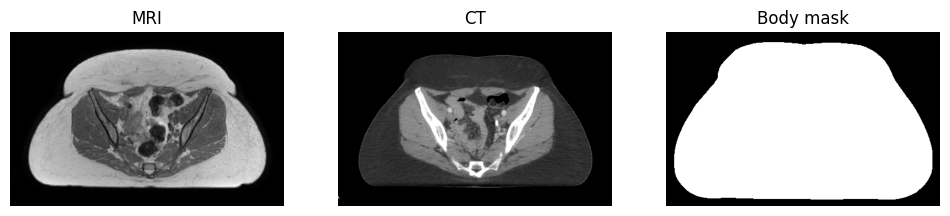

In [ ]:
import nibabel as nib
pid = patients[0]; d = f'{ROOT}/{pid}'
mr = nib.load(f'{d}/mr.nii.gz').get_fdata().astype(np.float32)
ct = nib.load(f'{d}/ct.nii.gz').get_fdata().astype(np.float32)
mk = nib.load(f'{d}/mask.nii.gz').get_fdata() > 0
print(pid, "| MR", mr.shape, round(mr.min()), round(mr.max()), "| CT", ct.shape, round(ct.min()), round(ct.max()))
k = mr.shape[2] // 2
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(mr[:, :, k].T, cmap='gray'); ax[0].set_title('MRI')
ax[1].imshow(ct[:, :, k].T, cmap='gray', vmin=-200, vmax=300); ax[1].set_title('CT')
ax[2].imshow(mk[:, :, k].T, cmap='gray'); ax[2].set_title('Body mask')
for a in ax: a.axis('off')
plt.show()

MRI sequence per centre

In [ ]:
cols = ['SeriesDescription', 'ScanningSequence', 'SequenceName', 'EchoTime', 'RepetitionTime',
        'MagneticFieldStrength', 'ManufacturerModelName']
for c, g in info.groupby('center'):
    print(f"\n=== Center {c} ({len(g)} patients) ===")
    for col in cols:
        print(col, "->", g[col].value_counts(dropna=False).head(3).to_dict())
print("\nPatients with a note (e.g. implants):")
print(info.loc[info['note'].notna(), ['ID', 'center', 'note']].to_string(index=False))


=== Center A (24 patients) ===
SeriesDescription -> {'Source Pelvis MRCAT IP': 14, 't MRCAT': 6, 'Pelvis MRCAT': 3}
ScanningSequence -> {'RM': 24}
SequenceName -> {'1': 14, 'empty': 10}
EchoTime -> {4.745: 12, 0.0: 7, 2.372: 3}
RepetitionTime -> {7.01440000534057: 12, 3.93020009994506: 3, 4.62440013885498: 3}
MagneticFieldStrength -> {1.5: 12, 3.0: 12}
ManufacturerModelName -> {'Ingenia': 24}

=== Center C (24 patients) ===
SeriesDescription -> {nan: 24}
ScanningSequence -> {'SE': 24}
SequenceName -> {'*spcR_80': 24}
EchoTime -> {202.0: 20, 100.0: 4}
RepetitionTime -> {1500.0: 18, 2000.0: 4, 1900.0: 1}
MagneticFieldStrength -> {3.0: 24}
ManufacturerModelName -> {nan: 24}

Patients with a note (e.g. implants):
    ID center            note
1PA025      A     hip implant
1PA144      A artifact on MRI
1PA170      A     hip implant


## 4. Train / validation / test split
The split is by **patient**, not by slice, because neighbouring slices are almost identical and a slice-level split would leak test data into training. It is stratified by center and saved to `split.json` so it never changes: 28 train, 8 validation, 12 test patients.

In [4]:
split_file = f'{PROJECT}/split.json'
if os.path.exists(split_file):
    split = json.load(open(split_file))
    print("Loaded existing split")
else:
    split = {'train': [], 'val': [], 'test': []}
    for c in ['A', 'C']:
        group = [p for p in patients if p[2] == c]
        random.shuffle(group)
        n_tr, n_va = int(0.6 * len(group)), int(0.2 * len(group))
        split['train'] += group[:n_tr]
        split['val']   += group[n_tr:n_tr + n_va]
        split['test']  += group[n_tr + n_va:]
    json.dump(split, open(split_file, 'w'), indent=2)
print({k: len(v) for k, v in split.items()})

Loaded existing split
{'train': 28, 'val': 8, 'test': 12}


## 5. Preprocessing
Each volume is cut into axial slices. CT is clipped to [-1000, 2000] HU and scaled to [-1, 1]; MRI is clipped at its 99.5th percentile and scaled to [-1, 1] per patient. Everything outside the body mask is set to air, which removes the CT couch. Slices are padded to square and resized to 256×256.

**v1 (baseline):** keeps every slice with a body in the CT.
**Alignment check:** red CT bone edges over the MRI should follow the bones.
**v2:** also drops slices where less than 50% of the body has MRI signal, because the MRI scan covers a shorter span than the CT and some slices have no MRI at all. The checks below show which slices were dropped (5286 → 5163 slices in total).

Preprocess V1

In [ ]:
import cv2, nibabel as nib
SIZE = 256
HU_MIN, HU_MAX = -1000, 2000
OUT = f'{PROJECT}/processed'

def square_resize(img, size, pad_val, interp):
    h, w = img.shape
    s = max(h, w)
    canvas = np.full((s, s), pad_val, dtype=img.dtype)
    y0, x0 = (s - h) // 2, (s - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = img
    return cv2.resize(canvas, (size, size), interpolation=interp)

def process_patient(pid):
    d = f'{ROOT}/{pid}'
    mr = nib.load(f'{d}/mr.nii.gz').get_fdata().astype(np.float32)
    ct = nib.load(f'{d}/ct.nii.gz').get_fdata().astype(np.float32)
    mk = nib.load(f'{d}/mask.nii.gz').get_fdata() > 0

    p995 = np.percentile(mr[mk], 99.5)
    mr = np.clip(mr, 0, p995) / p995 * 2 - 1
    mr[~mk] = -1

    ct = np.clip(ct, HU_MIN, HU_MAX)
    ct = (ct - HU_MIN) / (HU_MAX - HU_MIN) * 2 - 1
    ct[~mk] = -1

    MR, CT, MK = [], [], []
    for k in range(mr.shape[2]):
        if mk[:, :, k].sum() < 1000:
            continue
        MR.append(square_resize(mr[:, :, k].T, SIZE, -1, cv2.INTER_LINEAR))
        CT.append(square_resize(ct[:, :, k].T, SIZE, -1, cv2.INTER_LINEAR))
        MK.append(square_resize(mk[:, :, k].T.astype(np.uint8), SIZE, 0, cv2.INTER_NEAREST))

    np.savez_compressed(f'{OUT}/{pid}.npz',
                        mr=np.array(MR, dtype=np.float16),
                        ct=np.array(CT, dtype=np.float16),
                        mask=np.array(MK, dtype=np.uint8))

for p in tqdm(patients, desc='Preprocessing'):
    if not os.path.exists(f'{OUT}/{p}.npz'):     # resumable
        process_patient(p)
print("Done:", len(os.listdir(OUT)), "files in", OUT)

Preprocessing: 100%|██████████| 48/48 [01:58<00:00,  2.46s/it]

Done: 48 files in /content/drive/MyDrive/mri2ct_capstone/processed


Alignment check, before training

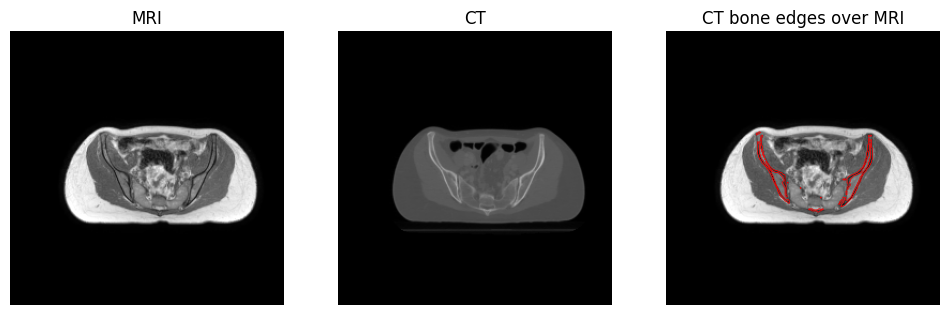

In [ ]:
z = np.load(f'{OUT}/{split["train"][0]}.npz')
i = len(z['mr']) // 2
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(z['mr'][i], cmap='gray', vmin=-1, vmax=1); ax[0].set_title('MRI')
ax[1].imshow(z['ct'][i], cmap='gray', vmin=-1, vmax=1); ax[1].set_title('CT')
ax[2].imshow(z['mr'][i], cmap='gray')
ax[2].contour(z['ct'][i].astype(np.float32) > 0.0, colors='r', linewidths=0.5)
ax[2].set_title('CT bone edges over MRI')
for a in ax: a.axis('off')
plt.show()

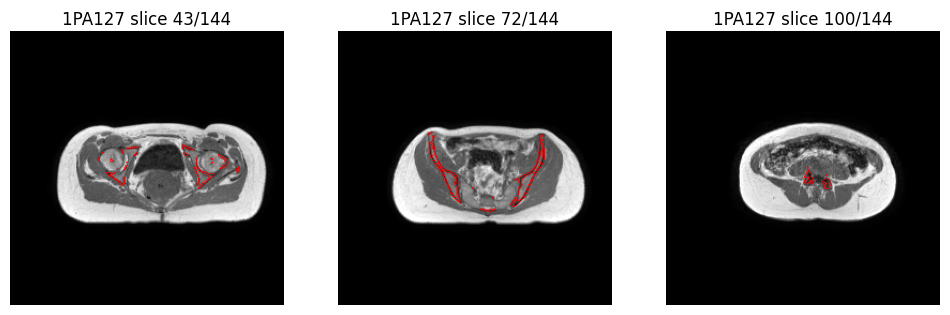

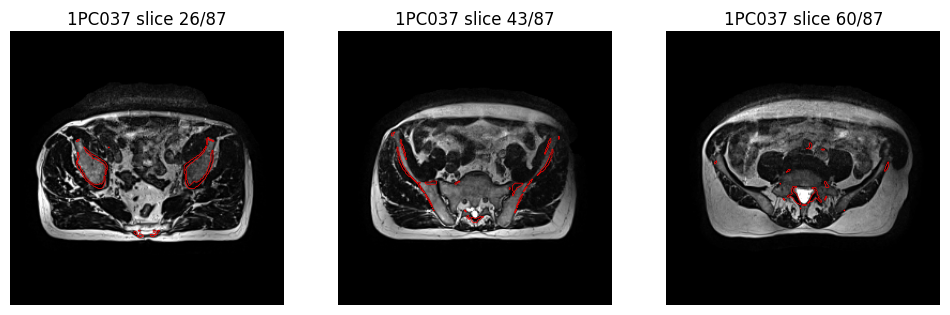

In [ ]:
def check(pid, fracs=(0.3, 0.5, 0.7)):
    z = np.load(f'{OUT}/{pid}.npz')
    n = len(z['mr'])
    fig, ax = plt.subplots(1, len(fracs), figsize=(4 * len(fracs), 4))
    for a, f in zip(ax, fracs):
        i = int(n * f)
        a.imshow(z['mr'][i], cmap='gray')
        a.contour(z['ct'][i].astype(np.float32) > 0.0, colors='r', linewidths=0.5)
        a.set_title(f'{pid} slice {i}/{n}'); a.axis('off')
    plt.show()

pA = next(p for p in split['train'] if p[2] == 'A')
pC = next(p for p in split['train'] if p[2] == 'C')
check(pA); check(pC)

v2 preprocessing:

In [5]:
import cv2, nibabel as nib
SIZE = 256
HU_MIN, HU_MAX = -1000, 2000
OUT2 = f'{PROJECT}/processed_v2'
os.makedirs(OUT2, exist_ok=True)
MIN_COVER = 0.5      # keep a slice only if >= 50% of its body pixels have MRI signal

def square_resize(img, size, pad_val, interp):
    h, w = img.shape
    s = max(h, w)
    canvas = np.full((s, s), pad_val, dtype=img.dtype)
    y0, x0 = (s - h) // 2, (s - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = img
    return cv2.resize(canvas, (size, size), interpolation=interp)

def process_patient_v2(pid):
    d = f'{ROOT}/{pid}'
    mr = nib.load(f'{d}/mr.nii.gz').get_fdata().astype(np.float32)
    ct = nib.load(f'{d}/ct.nii.gz').get_fdata().astype(np.float32)
    mk = nib.load(f'{d}/mask.nii.gz').get_fdata() > 0

    p995 = np.percentile(mr[mk], 99.5)
    thr = 0.03 * p995                                  # "has MRI signal" threshold
    mr_n = np.clip(mr, 0, p995) / p995 * 2 - 1;  mr_n[~mk] = -1
    ct_n = (np.clip(ct, HU_MIN, HU_MAX) - HU_MIN) / (HU_MAX - HU_MIN) * 2 - 1;  ct_n[~mk] = -1

    MR, CT, MK, dropped = [], [], [], []
    for k in range(mr.shape[2]):
        m = mk[:, :, k]
        if m.sum() < 1000:
            continue
        cover = (mr[:, :, k][m] > thr).mean()          # fraction of body pixels with MRI signal
        if cover < MIN_COVER:
            dropped.append(k); continue
        MR.append(square_resize(mr_n[:, :, k].T, SIZE, -1, cv2.INTER_LINEAR))
        CT.append(square_resize(ct_n[:, :, k].T, SIZE, -1, cv2.INTER_LINEAR))
        MK.append(square_resize(m.T.astype(np.uint8), SIZE, 0, cv2.INTER_NEAREST))

    np.savez_compressed(f'{OUT2}/{pid}.npz', mr=np.array(MR, dtype=np.float16),
                        ct=np.array(CT, dtype=np.float16), mask=np.array(MK, dtype=np.uint8))
    return len(MR), len(dropped)

kept_total = dropped_total = 0
for p in tqdm(patients, desc='Preprocessing v2'):
    if not os.path.exists(f'{OUT2}/{p}.npz'):
        k, d = process_patient_v2(p)
        kept_total += k; dropped_total += d
print(f"Done: {len(os.listdir(OUT2))} files | this run kept {kept_total}, dropped {dropped_total} slices")

Preprocessing v2: 100%|██████████| 48/48 [00:00<00:00, 1600.52it/s]

Done: 48 files | this run kept 0, dropped 0 slices


Check that the filter did its job. This shows the first and last kept slice for three patients. Both should contain real MRI signal and not be blank:

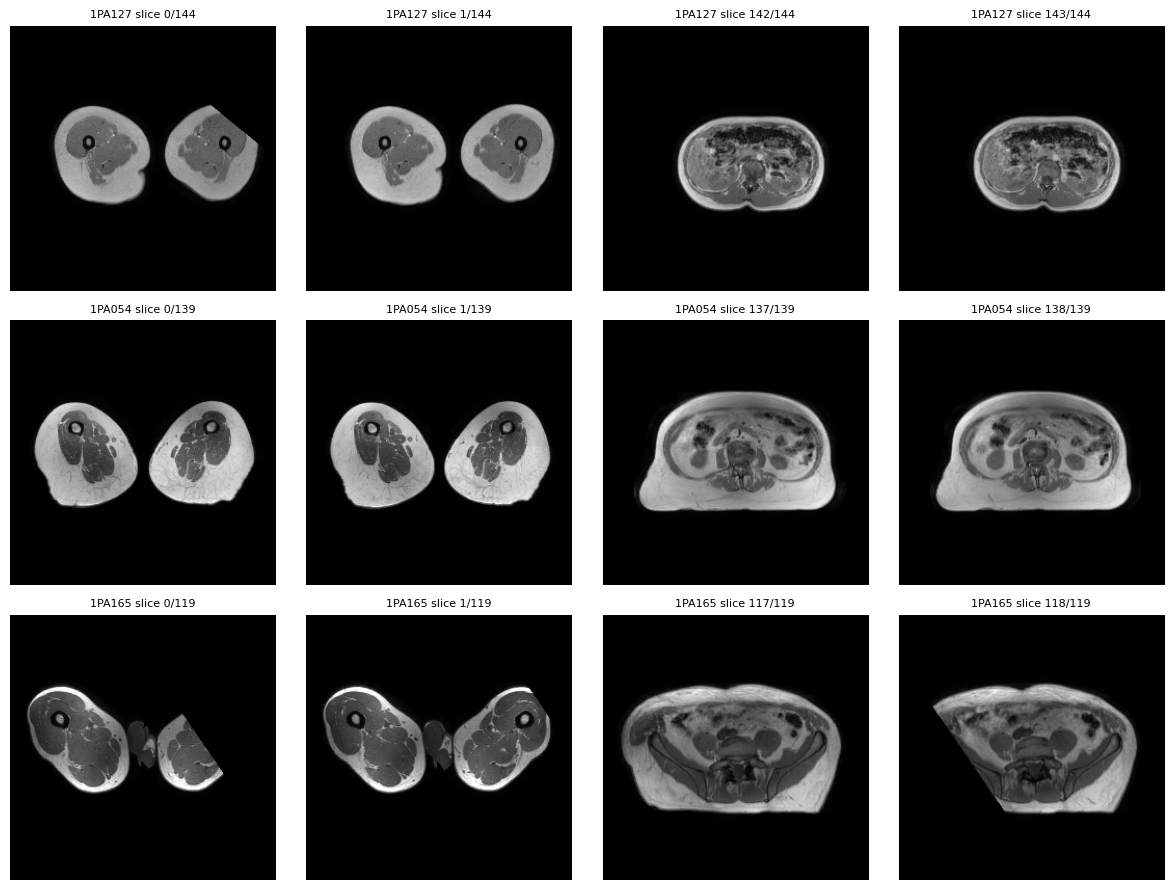

In [ ]:
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for r, p in enumerate([split['train'][0], split['val'][0], split['test'][0]]):
    z = np.load(f'{OUT2}/{p}.npz'); n = len(z['mr'])
    for c, i in enumerate([0, 1, n - 2, n - 1]):
        ax[r, c].imshow(z['mr'][i], cmap='gray', vmin=-1, vmax=1)
        ax[r, c].set_title(f'{p} slice {i}/{n}', fontsize=8); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

compare slice counts, v1 vs v2

In [ ]:
for name, d in [('v1', f'{PROJECT}/processed'), ('v2', OUT2)]:
    n = sum(len(np.load(f'{d}/{p}.npz')['mr']) for p in patients)
    print(name, "total slices:", n)

v1 total slices: 5286
v2 total slices: 5163


Check 1: where the drops happened

In [ ]:
import pandas as pd
diff = {p: len(np.load(f'{PROJECT}/processed/{p}.npz')['mr']) - len(np.load(f'{OUT2}/{p}.npz')['mr'])
        for p in patients}
s = pd.Series(diff)
print(s.describe().round(1))
print("patients with 0 dropped:", (s == 0).sum(), "of", len(s))
print("\nmost dropped:\n", s.sort_values(ascending=False).head(5))
print("\ndropped by split:", {k: int(sum(diff[p] for p in v)) for k, v in split.items()})

count    48.0
mean      2.6
std       2.5
min       0.0
25%       1.0
50%       2.0
75%       3.0
max      12.0
dtype: float64
patients with 0 dropped: 8 of 48

most dropped:
 1PC040    12
1PC059    12
1PA049     6
1PA060     5
1PC066     5
dtype: int64

dropped by split: {'train': 66, 'val': 16, 'test': 41}


dropped slice indices: [0, 1, 2, 3, 4, 5, 6, 85, 86, 87, 88, 89] | coverage values: [np.float64(0.0), np.float64(0.15), np.float64(0.25), np.float64(0.29), np.float64(0.33), np.float64(0.42), np.float64(0.48), np.float64(0.46), np.float64(0.37), np.float64(0.3), np.float64(0.24), np.float64(0.15)]


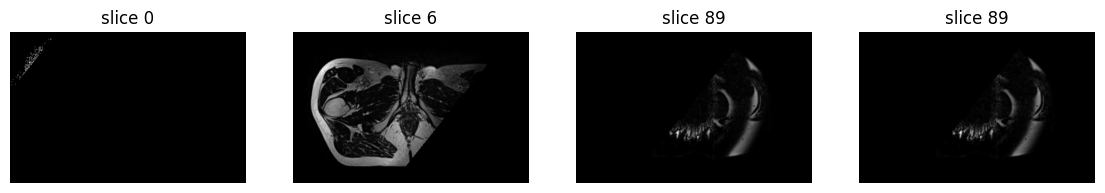

In [ ]:
pid = '1PC040'
d = f'{ROOT}/{pid}'
mr = nib.load(f'{d}/mr.nii.gz').get_fdata().astype(np.float32)
mk = nib.load(f'{d}/mask.nii.gz').get_fdata() > 0
thr = 0.03 * np.percentile(mr[mk], 99.5)
cover = [(mr[:, :, k][mk[:, :, k]] > thr).mean() if mk[:, :, k].sum() >= 1000 else None
         for k in range(mr.shape[2])]
bad = [k for k, c in enumerate(cover) if c is not None and c < 0.5]
print("dropped slice indices:", bad, "| coverage values:", [round(cover[k], 2) for k in bad])

fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for a, k in zip(ax, [bad[0], bad[len(bad)//2], bad[-1], min(bad[-1] + 1, mr.shape[2] - 1)]):
    a.imshow(mr[:, :, k].T, cmap='gray'); a.set_title(f'slice {k}'); a.axis('off')
plt.show()

## 6. Experiment settings
`VERSION` selects the data (`v1` = all slices, `v2` = coverage-filtered) and the matching checkpoint, figure and CSV folders, so the two runs never overwrite each other. `RETRAIN = False` loads the saved model instead of training.

In [21]:
import os, json, random, glob
import numpy as np, matplotlib.pyplot as plt
from tqdm import tqdm

VERSION = 'v2'          # 'v1' = original data, 'v2' = coverage-filtered data
RETRAIN = False         # False = load the saved model. True = train (overwrites best.pt!)

SUF = '' if VERSION == 'v1' else '_v2'
OUT = f'{PROJECT}/processed{SUF}'
CK  = f'{PROJECT}/checkpoints{SUF}'
FIG = f'{PROJECT}/figures{SUF}'
for d in (CK, FIG): os.makedirs(d, exist_ok=True)

HU_MIN, HU_MAX = -1000, 2000
split = json.load(open(f'{PROJECT}/split.json'))
random.seed(42); np.random.seed(42)

print(VERSION, "| data:", OUT, "| checkpoints:", CK)
print({k: len(v) for k, v in split.items()}, "|", len(glob.glob(f'{OUT}/*.npz')), "processed files")
print(RETRAIN)    # should print False

v2 | data: /content/drive/MyDrive/mri2ct_capstone/processed_v2 | checkpoints: /content/drive/MyDrive/mri2ct_capstone/checkpoints_v2
{'train': 28, 'val': 8, 'test': 12} | 48 processed files
False


## 7. Datasets and data loaders
All preprocessed slices are loaded into RAM. The only augmentation is a random left-right flip applied to the MRI, CT and mask together, so the pair stays aligned. Batch size 16 fits the T4.





In [7]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

class SliceDS(Dataset):
    def __init__(self, pids, augment=False):
        mr, ct, mk = [], [], []
        for p in pids:
            z = np.load(f'{OUT}/{p}.npz')
            mr.append(z['mr']); ct.append(z['ct']); mk.append(z['mask'])
        self.mr, self.ct, self.mk = map(np.concatenate, (mr, ct, mk))
        self.augment = augment

    def __len__(self): return len(self.mr)

    def __getitem__(self, i):
        mr = torch.from_numpy(self.mr[i].astype(np.float32))[None]
        ct = torch.from_numpy(self.ct[i].astype(np.float32))[None]
        mk = torch.from_numpy(self.mk[i].astype(np.float32))[None]
        if self.augment and torch.rand(1).item() < 0.5:     # same flip for the whole pair
            mr, ct, mk = mr.flip(-1), ct.flip(-1), mk.flip(-1)
        return mr, ct, mk

train_ds = SliceDS(split['train'], augment=True)
val_ds   = SliceDS(split['val'])
test_ds  = SliceDS(split['test'])
print(f"slices -> train {len(train_ds)}, val {len(val_ds)}, test {len(test_ds)}")

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, drop_last=True,
                      num_workers=2, pin_memory=True, persistent_workers=True)
val_dl   = DataLoader(val_ds, batch_size=32, shuffle=False,
                      num_workers=2, pin_memory=True, persistent_workers=True)

mr, ct, mk = next(iter(train_dl))
print("batch:", mr.shape, "| MRI range", round(mr.min().item(), 2), round(mr.max().item(), 2),
      "| CT range", round(ct.min().item(), 2), round(ct.max().item(), 2))

Device: cuda Tesla T4
slices -> train 3040, val 887, test 1236
batch: torch.Size([16, 1, 256, 256]) | MRI range -1.0 1.0 | CT range -1.0 0.66


## 8. Models
**Generator:** a U-Net (encoder → decoder, 54.4M parameters). Skip connections carry fine detail such as bone edges straight from the encoder to the decoder.
**Discriminator:** a PatchGAN (2.8M parameters) that judges realism per patch. It sees the MRI and CT stacked together, which makes the GAN *conditional*.

In [8]:
class Down(nn.Module):
    def __init__(self, i, o, norm=True):
        super().__init__()
        layers = [nn.Conv2d(i, o, 4, 2, 1, bias=False)]
        if norm: layers.append(nn.InstanceNorm2d(o))
        layers.append(nn.LeakyReLU(0.2, True))
        self.m = nn.Sequential(*layers)
    def forward(self, x): return self.m(x)

class Up(nn.Module):
    def __init__(self, i, o, dropout=False):
        super().__init__()
        layers = [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.InstanceNorm2d(o)]
        if dropout: layers.append(nn.Dropout(0.5))
        layers.append(nn.ReLU(True))
        self.m = nn.Sequential(*layers)
    def forward(self, x, skip):
        return torch.cat([self.m(x), skip], dim=1)      # skip connection

class UNetGenerator(nn.Module):
    def __init__(self, in_ch=1, out_ch=1):
        super().__init__()
        self.d1 = Down(in_ch, 64, norm=False)
        self.d2 = Down(64, 128);  self.d3 = Down(128, 256)
        self.d4 = Down(256, 512); self.d5 = Down(512, 512)
        self.d6 = Down(512, 512); self.d7 = Down(512, 512)
        self.d8 = Down(512, 512, norm=False)
        self.u1 = Up(512, 512, True);  self.u2 = Up(1024, 512, True)
        self.u3 = Up(1024, 512, True); self.u4 = Up(1024, 512)
        self.u5 = Up(1024, 256);       self.u6 = Up(512, 128)
        self.u7 = Up(256, 64)
        self.final = nn.Sequential(nn.ConvTranspose2d(128, out_ch, 4, 2, 1), nn.Tanh())

    def forward(self, x):
        d1 = self.d1(x); d2 = self.d2(d1); d3 = self.d3(d2); d4 = self.d4(d3)
        d5 = self.d5(d4); d6 = self.d6(d5); d7 = self.d7(d6); d8 = self.d8(d7)
        x = self.u1(d8, d7); x = self.u2(x, d6); x = self.u3(x, d5)
        x = self.u4(x, d4);  x = self.u5(x, d3); x = self.u6(x, d2)
        x = self.u7(x, d1)
        return self.final(x)

class PatchDiscriminator(nn.Module):
    def __init__(self, in_ch=2):                         # MRI + CT stacked
        super().__init__()
        def blk(i, o, stride, norm=True):
            l = [nn.Conv2d(i, o, 4, stride, 1, bias=False)]
            if norm: l.append(nn.InstanceNorm2d(o))
            l.append(nn.LeakyReLU(0.2, True))
            return l
        self.m = nn.Sequential(*blk(in_ch, 64, 2, False), *blk(64, 128, 2),
                               *blk(128, 256, 2), *blk(256, 512, 1),
                               nn.Conv2d(512, 1, 4, 1, 1))
    def forward(self, mr, ct):
        return self.m(torch.cat([mr, ct], dim=1))

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)

G = UNetGenerator().to(device); G.apply(init_weights)
D = PatchDiscriminator().to(device); D.apply(init_weights)

with torch.no_grad():
    x = torch.randn(2, 1, 256, 256).to(device)
    print("G out:", G(x).shape, "| D out:", D(x, G(x)).shape)
print(f"G: {sum(p.numel() for p in G.parameters())/1e6:.1f}M params | D: {sum(p.numel() for p in D.parameters())/1e6:.1f}M params")

G out: torch.Size([2, 1, 256, 256]) | D out: torch.Size([2, 1, 30, 30])
G: 54.4M params | D: 2.8M params


## 9. Training
Loss for the generator = adversarial (BCE) + 100 × L1. The adversarial term gives sharp texture and L1 keeps the anatomy correct. Adam (lr 2e-4), mixed precision, 40 epochs at about 37 s per epoch on a T4. The checkpoint with the lowest validation MAE (epoch 38, 97.7 HU) is kept as `best.pt`.

⚠️ **Setting `RETRAIN = True` overwrites `best.pt`.** To retrain from scratch, first delete `last.pt` and `best.pt` from the checkpoint folder.

**Reading the curves:** the discriminator loss stays near 0.69 (its "guessing" value), so the adversarial term gives only weak feedback and L1 dominates. Validation MAE falls quickly in the first ~20 epochs, then plateaus with ±3 HU noise. The **baseline** predicts one constant HU value inside the body; the trained model should be far below it. The **overfitting check** compares training and validation error: a large gap means the model fits the training patients much better than unseen ones.

Epoch 1: G=12.554  D=0.596  val MAE≈134.1 HU  (34s)


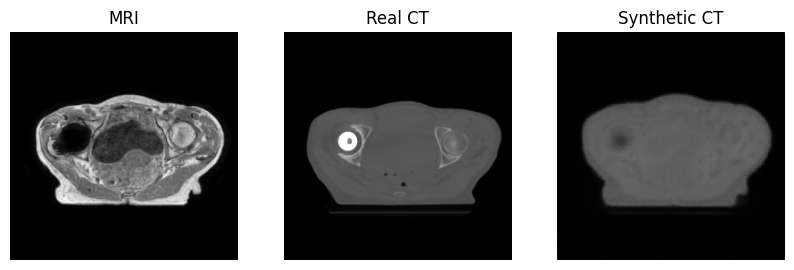

Epoch 2: G=4.221  D=0.616  val MAE≈113.8 HU  (35s)


Epoch 3: G=3.563  D=0.650  val MAE≈123.0 HU  (38s)


Epoch 4: G=3.136  D=0.662  val MAE≈114.7 HU  (37s)


Epoch 5: G=2.897  D=0.653  val MAE≈111.6 HU  (37s)


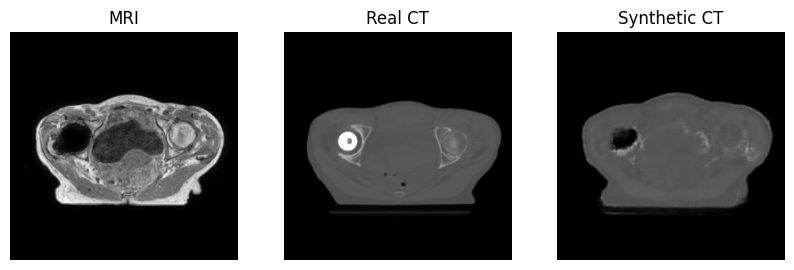

Epoch 6: G=2.734  D=0.652  val MAE≈114.4 HU  (37s)


Epoch 7: G=2.449  D=0.711  val MAE≈113.7 HU  (37s)


Epoch 8: G=2.437  D=0.660  val MAE≈110.6 HU  (37s)


Epoch 9: G=2.407  D=0.657  val MAE≈109.2 HU  (37s)


Epoch 10: G=2.340  D=0.679  val MAE≈106.4 HU  (37s)


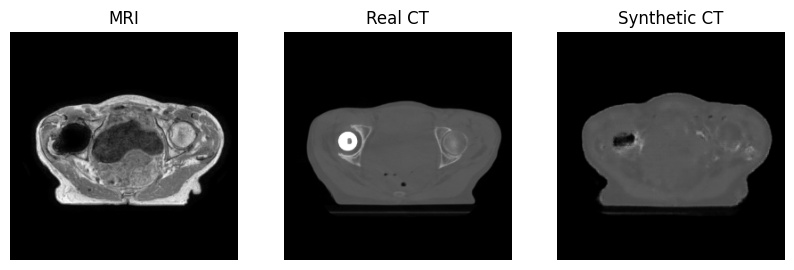

Epoch 11: G=2.259  D=0.654  val MAE≈107.8 HU  (37s)


Epoch 12: G=2.249  D=0.670  val MAE≈102.8 HU  (37s)


Epoch 13: G=2.149  D=0.665  val MAE≈105.5 HU  (37s)


Epoch 14: G=2.139  D=0.663  val MAE≈107.7 HU  (38s)


Epoch 15: G=2.035  D=0.683  val MAE≈105.1 HU  (36s)


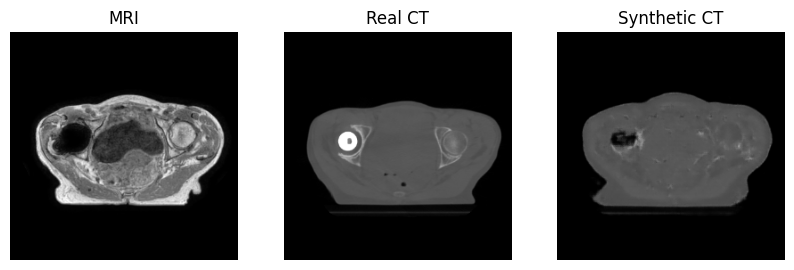

Epoch 16: G=2.024  D=0.686  val MAE≈103.1 HU  (37s)


Epoch 17: G=2.005  D=0.663  val MAE≈107.4 HU  (37s)


Epoch 18: G=1.992  D=0.673  val MAE≈103.8 HU  (37s)


Epoch 19: G=1.944  D=0.671  val MAE≈103.5 HU  (37s)


Epoch 20: G=1.946  D=0.689  val MAE≈98.4 HU  (36s)


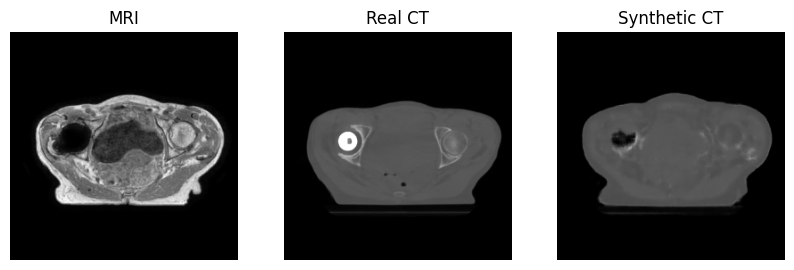

Epoch 21: G=1.840  D=0.671  val MAE≈104.5 HU  (37s)


Epoch 22: G=1.877  D=0.675  val MAE≈103.6 HU  (37s)


Epoch 23: G=1.861  D=0.671  val MAE≈103.6 HU  (37s)


Epoch 24: G=1.835  D=0.677  val MAE≈103.6 HU  (37s)


Epoch 25: G=1.773  D=0.702  val MAE≈100.1 HU  (37s)


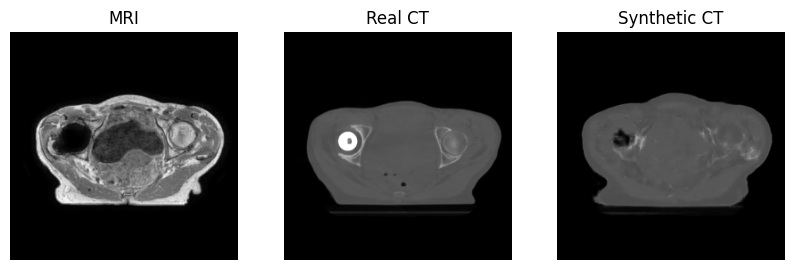

Epoch 26: G=1.746  D=0.683  val MAE≈103.3 HU  (37s)


Epoch 27: G=1.749  D=0.674  val MAE≈101.5 HU  (37s)


Epoch 28: G=1.760  D=0.675  val MAE≈104.2 HU  (36s)


Epoch 29: G=1.743  D=0.677  val MAE≈100.5 HU  (37s)


Epoch 30: G=1.697  D=0.687  val MAE≈100.4 HU  (37s)


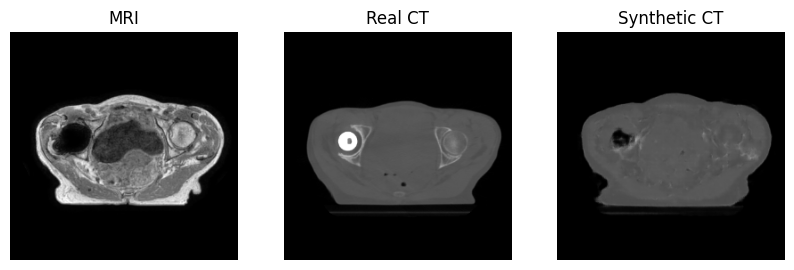

Epoch 31: G=1.714  D=0.677  val MAE≈101.7 HU  (37s)


Epoch 32: G=1.683  D=0.714  val MAE≈98.0 HU  (37s)


Epoch 33: G=1.540  D=0.689  val MAE≈98.0 HU  (37s)


Epoch 34: G=1.565  D=0.686  val MAE≈100.4 HU  (37s)


Epoch 35: G=1.627  D=0.677  val MAE≈101.0 HU  (37s)


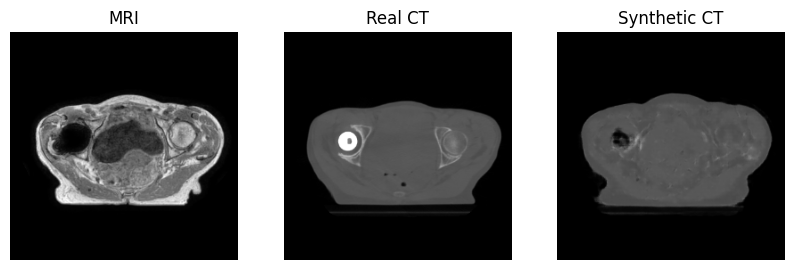

Epoch 36: G=1.637  D=0.693  val MAE≈98.7 HU  (37s)


Epoch 37: G=1.562  D=0.682  val MAE≈103.3 HU  (37s)


Epoch 38: G=1.612  D=0.690  val MAE≈97.7 HU  (37s)


Epoch 39: G=1.577  D=0.680  val MAE≈101.9 HU  (38s)


Epoch 40: G=1.602  D=0.682  val MAE≈99.5 HU  (37s)


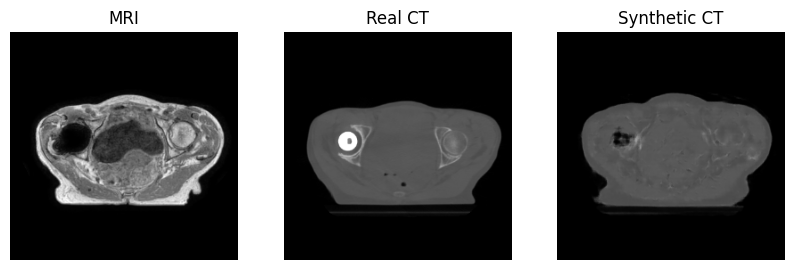

In [ ]:
import time, torch.nn as nn

EPOCHS, LR, LAMBDA = 40, 2e-4, 100
USE_AMP = True
HU_PER_UNIT = (HU_MAX - HU_MIN) / 2     # 1 normalized unit = 1500 HU

bce, l1 = nn.BCEWithLogitsLoss(), nn.L1Loss()
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
scaler_G = torch.amp.GradScaler('cuda', enabled=USE_AMP)
scaler_D = torch.amp.GradScaler('cuda', enabled=USE_AMP)

ckpt_path = f'{CK}/last.pt'
best_path = f'{CK}/best.pt'
start, best_val, history = 0, 1e9, []

if RETRAIN and os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device)
    G.load_state_dict(ck['G']); D.load_state_dict(ck['D'])
    opt_G.load_state_dict(ck['opt_G']); opt_D.load_state_dict(ck['opt_D'])
    start, best_val, history = ck['epoch'] + 1, ck['best_val'], ck['history']
    print("Resumed from epoch", start)

@torch.no_grad()
def validate():
    G.eval(); tot, n = 0.0, 0.0
    for mr, ct, mk in val_dl:
        mr, ct, mk = mr.to(device), ct.to(device), mk.to(device)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            fake = G(mr)
        tot += ((fake.float() - ct).abs() * mk).sum().item()
        n += mk.sum().item()
    G.train()
    return tot / n * HU_PER_UNIT                    # masked MAE in HU

for epoch in range(start, EPOCHS if RETRAIN else 0):
    t0 = time.time()
    gl = dl_ = 0.0
    for mr, ct, _ in tqdm(train_dl, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False):
        mr = mr.to(device, non_blocking=True); ct = ct.to(device, non_blocking=True)

        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            fake = G(mr)
            # ---- Discriminator step ----
            p_real = D(mr, ct)
            p_fake = D(mr, fake.detach())
            loss_D = 0.5 * (bce(p_real, torch.ones_like(p_real)) +
                            bce(p_fake, torch.zeros_like(p_fake)))
        opt_D.zero_grad(set_to_none=True)
        scaler_D.scale(loss_D).backward()
        scaler_D.step(opt_D); scaler_D.update()

        # ---- Generator step ----
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            p_fake = D(mr, fake)
            loss_adv = bce(p_fake, torch.ones_like(p_fake))
        loss_l1 = l1(fake.float(), ct)
        loss_G = loss_adv.float() + LAMBDA * loss_l1
        opt_G.zero_grad(set_to_none=True)
        scaler_G.scale(loss_G).backward()
        scaler_G.step(opt_G); scaler_G.update()

        gl += loss_G.item(); dl_ += loss_D.item()

    val_mae = validate()
    history.append(dict(epoch=epoch, G=gl/len(train_dl), D=dl_/len(train_dl), val_mae=val_mae))
    print(f"Epoch {epoch+1}: G={gl/len(train_dl):.3f}  D={dl_/len(train_dl):.3f}  "
          f"val MAE≈{val_mae:.1f} HU  ({time.time()-t0:.0f}s)")

    if val_mae < best_val:
        best_val = val_mae; torch.save(G.state_dict(), best_path)
    torch.save(dict(G=G.state_dict(), D=D.state_dict(), opt_G=opt_G.state_dict(),
                    opt_D=opt_D.state_dict(), epoch=epoch, best_val=best_val,
                    history=history), ckpt_path)

    if (epoch + 1) % 5 == 0 or epoch == 0:          # quick visual check
        G.eval()
        with torch.no_grad():
            m, c, _ = val_ds[len(val_ds)//2]
            fk = G(m[None].to(device)).float().cpu()[0, 0]
        G.train()
        fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
        for a, im, t in zip(ax, [m[0], c[0], fk], ['MRI', 'Real CT', 'Synthetic CT']):
            a.imshow(im, cmap='gray', vmin=-1, vmax=1); a.set_title(t); a.axis('off')
        plt.show()

Training curves

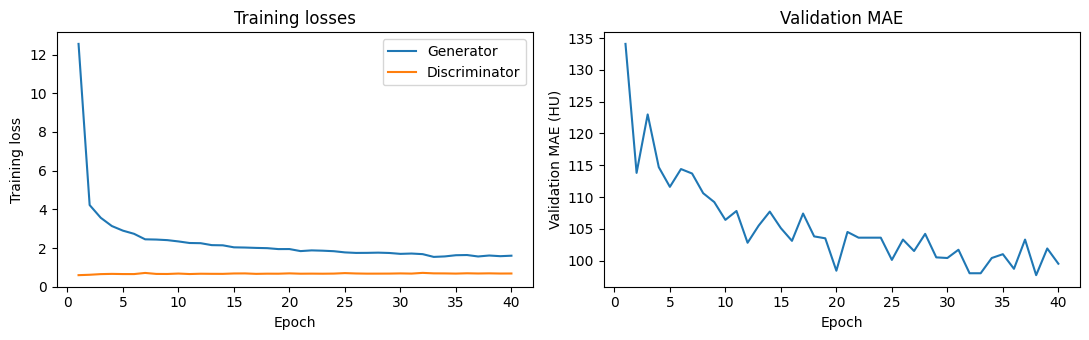

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ep = np.arange(1, len(history) + 1)
ax[0].plot(ep, [h['G'] for h in history], label='Generator')
ax[0].plot(ep, [h['D'] for h in history], label='Discriminator')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Training loss'); ax[0].legend(); ax[0].set_title('Training losses')
ax[1].plot(ep, [h['val_mae'] for h in history])
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Validation MAE (HU)'); ax[1].set_title('Validation MAE')
plt.tight_layout(); plt.savefig(f'{FIG}/training_curves.png', dpi=150); plt.show()

In [ ]:
vals = []
for p in split['train']:
    z = np.load(f'{OUT}/{p}.npz')
    ct, mk = z['ct'][:, ::4, ::4].astype(np.float32), z['mask'][:, ::4, ::4] > 0
    vals.append(ct[mk])                                # body pixels only
mean_in_body = np.concatenate(vals).mean()

tot = n = 0.0
for mr, ct, mk in val_dl:
    tot += ((ct - mean_in_body).abs() * mk).sum().item(); n += mk.sum().item()
print("constant-in-body baseline val MAE ≈", round(tot / n * HU_PER_UNIT, 1), "HU")

constant-in-body baseline val MAE ≈ 332.5 HU


Overfitting check

In [ ]:
G.load_state_dict(torch.load(best_path, map_location=device)); G.eval()

@torch.no_grad()
def masked_mae(loader, max_batches=60):
    tot = n = 0.0
    for b, (mr, ct, mk) in enumerate(loader):
        if b >= max_batches: break
        mr, ct, mk = mr.to(device), ct.to(device), mk.to(device)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            fake = G(mr)
        tot += ((fake.float() - ct).abs() * mk).sum().item(); n += mk.sum().item()
    return tot / n * HU_PER_UNIT

print("train MAE ≈", round(masked_mae(train_dl), 1), "HU | val MAE ≈", round(masked_mae(val_dl), 1), "HU")

train MAE ≈ 26.3 HU | val MAE ≈ 97.7 HU


In [ ]:
val = [h['val_mae'] for h in history]
best_ep = int(np.argmin(val))
print("best epoch:", best_ep + 1, "| val MAE:", round(val[best_ep], 1))
print("val MAE by epoch:", [round(v) for v in val])

best epoch: 38 | val MAE: 97.7
val MAE by epoch: [134, 114, 123, 115, 112, 114, 114, 111, 109, 106, 108, 103, 106, 108, 105, 103, 107, 104, 103, 98, 104, 104, 104, 104, 100, 103, 102, 104, 100, 100, 102, 98, 98, 100, 101, 99, 103, 98, 102, 100]


## 10. Evaluation on the test patients
Predictions are converted back to Hounsfield Units and scored inside the body mask. Results are mean ± std over the 12 test patients, so they are noisy; a few HU differences between experiments are not meaningful.

- **MAE** = average absolute HU error (lower is better); **PSNR** = overall signal quality (higher is better); **SSIM** = structural similarity of edges and texture, 0–1 (higher is better).
- **HU-region accuracy:** regions are defined from the real CT (air < -500, soft tissue -100 to 200, bone > 250 HU; these thresholds are my choice). It is a lightweight proxy for dose relevance, not a dose calculation.
- **Failure cases:** the four worst slices by MAE.

In [14]:
import pandas as pd
from skimage.metrics import structural_similarity as ssim

G.load_state_dict(torch.load(best_path, map_location=device)); G.eval()
RANGE = HU_MAX - HU_MIN
def to_hu(x): return (x + 1) / 2 * RANGE + HU_MIN

@torch.no_grad()
def predict_patient(pid):
    z = np.load(f'{OUT}/{pid}.npz')
    mr = torch.from_numpy(z['mr'].astype(np.float32))[:, None]
    out = []
    for i in range(0, len(mr), 16):
        out.append(G(mr[i:i+16].to(device)).float().cpu())
    sct = to_hu(torch.cat(out)[:, 0].numpy())
    return z['mr'].astype(np.float32), to_hu(z['ct'].astype(np.float32)), sct, z['mask'] > 0

preds = {pid: predict_patient(pid) for pid in tqdm(split['test'], desc='Predicting')}

rows, slice_records = [], []
for pid, (mr, ct, sct, mk) in preds.items():
    maes, psnrs, ssims = [], [], []
    for i in range(len(ct)):
        m = mk[i]
        err = np.abs(sct[i] - ct[i])[m].mean()
        mse = ((sct[i] - ct[i]) ** 2)[m].mean()
        maes.append(err); psnrs.append(10 * np.log10(RANGE ** 2 / mse))
        s_masked = np.where(m, sct[i], HU_MIN)           # background = air in both images
        ssims.append(ssim(ct[i], s_masked, data_range=RANGE))
        slice_records.append((pid, i, err))
    rows.append((pid, np.mean(maes), np.mean(psnrs), np.mean(ssims)))

df = pd.DataFrame(rows, columns=['patient', 'MAE_HU', 'PSNR_dB', 'SSIM'])
df['center'] = df['patient'].str[2]
print(df.round(3))
print("\nOverall mean ± std")
print(df[['MAE_HU', 'PSNR_dB', 'SSIM']].agg(['mean', 'std']).round(3))
print("\nPer center")
print(df.groupby('center')[['MAE_HU', 'PSNR_dB', 'SSIM']].agg(['mean', 'std']).round(2))
df.to_csv(f'{PROJECT}/test_metrics{SUF}.csv', index=False)

Predicting: 100%|██████████| 12/12 [00:12<00:00,  1.07s/it]


   patient      MAE_HU    PSNR_dB   SSIM center
0   1PA165   71.313004  25.690001  0.867      A
1   1PA049   97.214996  24.141001  0.822      A
2   1PA052  107.897003  22.767000  0.782      A
3   1PA009   91.777000  23.400000  0.844      A
4   1PA024   97.121002  23.233999  0.829      A
5   1PA170   79.050003  25.148001  0.861      A
6   1PC040   90.302002  24.676001  0.833      C
7   1PC045   81.390999  25.173000  0.817      C
8   1PC022   79.563004  25.264999  0.822      C
9   1PC000   89.065002  24.507000  0.785      C
10  1PC032   79.647003  24.990999  0.851      C
11  1PC066   87.391998  24.320000  0.800      C

Overall mean ± std
      MAE_HU  PSNR_dB   SSIM
mean  87.644   24.443  0.826
std   10.121    0.909  0.027

Per center
           MAE_HU           PSNR_dB        SSIM      
             mean    std       mean   std  mean   std
center                                               
A       90.730003  13.36  24.059999  1.15  0.83  0.03
C       84.559998   4.91  24.820000  0.38

HU-region accuracy (the dose-relevance check)

In [15]:
REGIONS = {'air':         lambda c: c < -500,
           'soft_tissue': lambda c: (c >= -100) & (c <= 200),
           'bone':        lambda c: c > 250}

reg_rows = []
for pid, (mr, ct, sct, mk) in preds.items():
    for name, fn in REGIONS.items():
        sel = fn(ct) & mk
        if sel.sum() < 100: continue
        reg_rows.append(dict(patient=pid, center=pid[2], region=name,
                             real_mean=ct[sel].mean(), sct_mean=sct[sel].mean(),
                             real_median=np.median(ct[sel]), sct_median=np.median(sct[sel]),
                             MAE=np.abs(sct[sel] - ct[sel]).mean()))
reg = pd.DataFrame(reg_rows)

cols = ['real_mean', 'sct_mean', 'real_median', 'sct_median', 'MAE']
summary = reg.groupby('region')[cols].mean().round(1)
summary['mean_bias'] = (summary['sct_mean'] - summary['real_mean']).round(1)
print(summary)
print("\nBy center")
print(reg.groupby(['region', 'center'])[['MAE']].mean().round(1))
summary.to_csv(f'{PROJECT}/region_hu_summary{SUF}.csv')

              real_mean    sct_mean  real_median  sct_median         MAE  \
region                                                                     
air         -920.900024 -846.900024  -981.799988      -979.5  120.300003   
bone         499.200012  236.000000   423.500000       172.5  302.100006   
soft_tissue   -1.900000  -12.900000    10.200000         7.8   55.900002   

              mean_bias  
region                   
air           74.000000  
bone        -263.200012  
soft_tissue  -11.000000  

By center
                           MAE
region      center            
air         A       124.599998
            C       115.900002
bone        A       295.799988
            C       308.399994
soft_tissue A        60.700001
            C        51.000000


Qualitative panels and failure cases

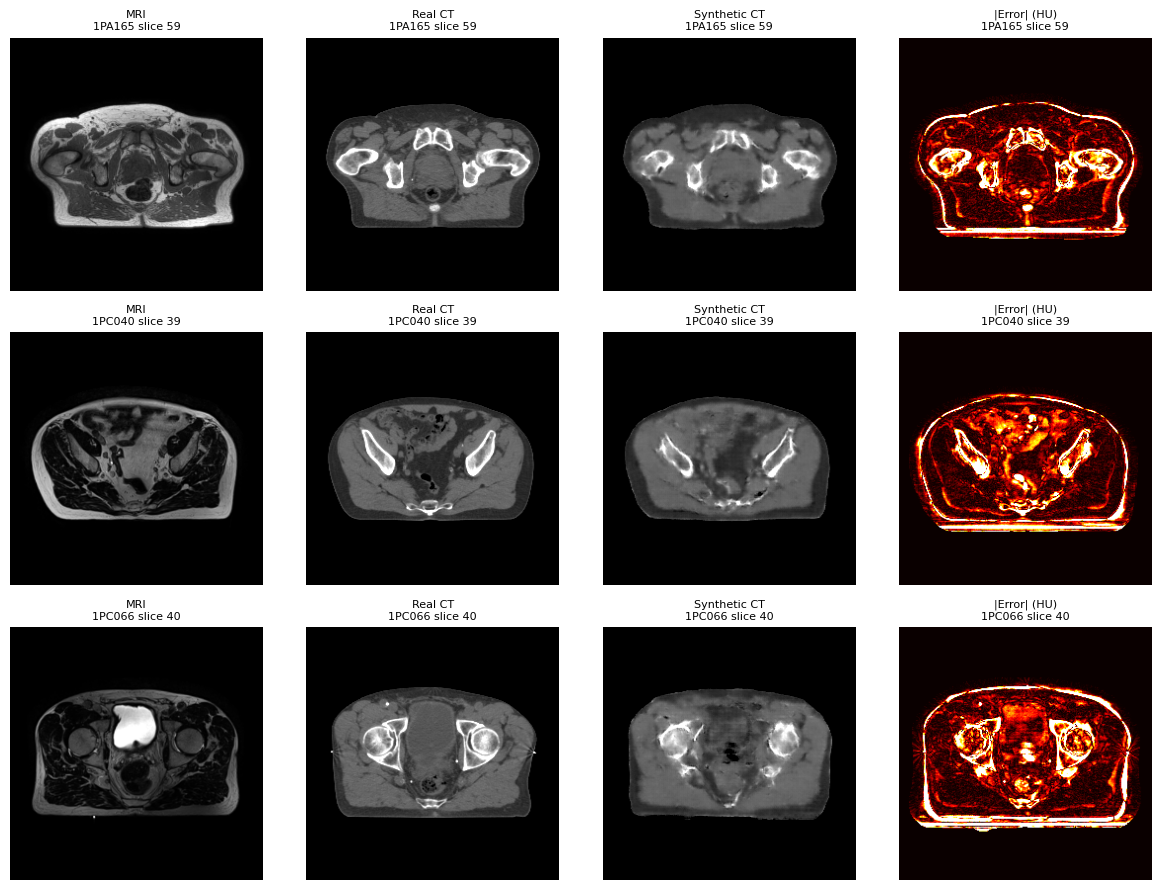

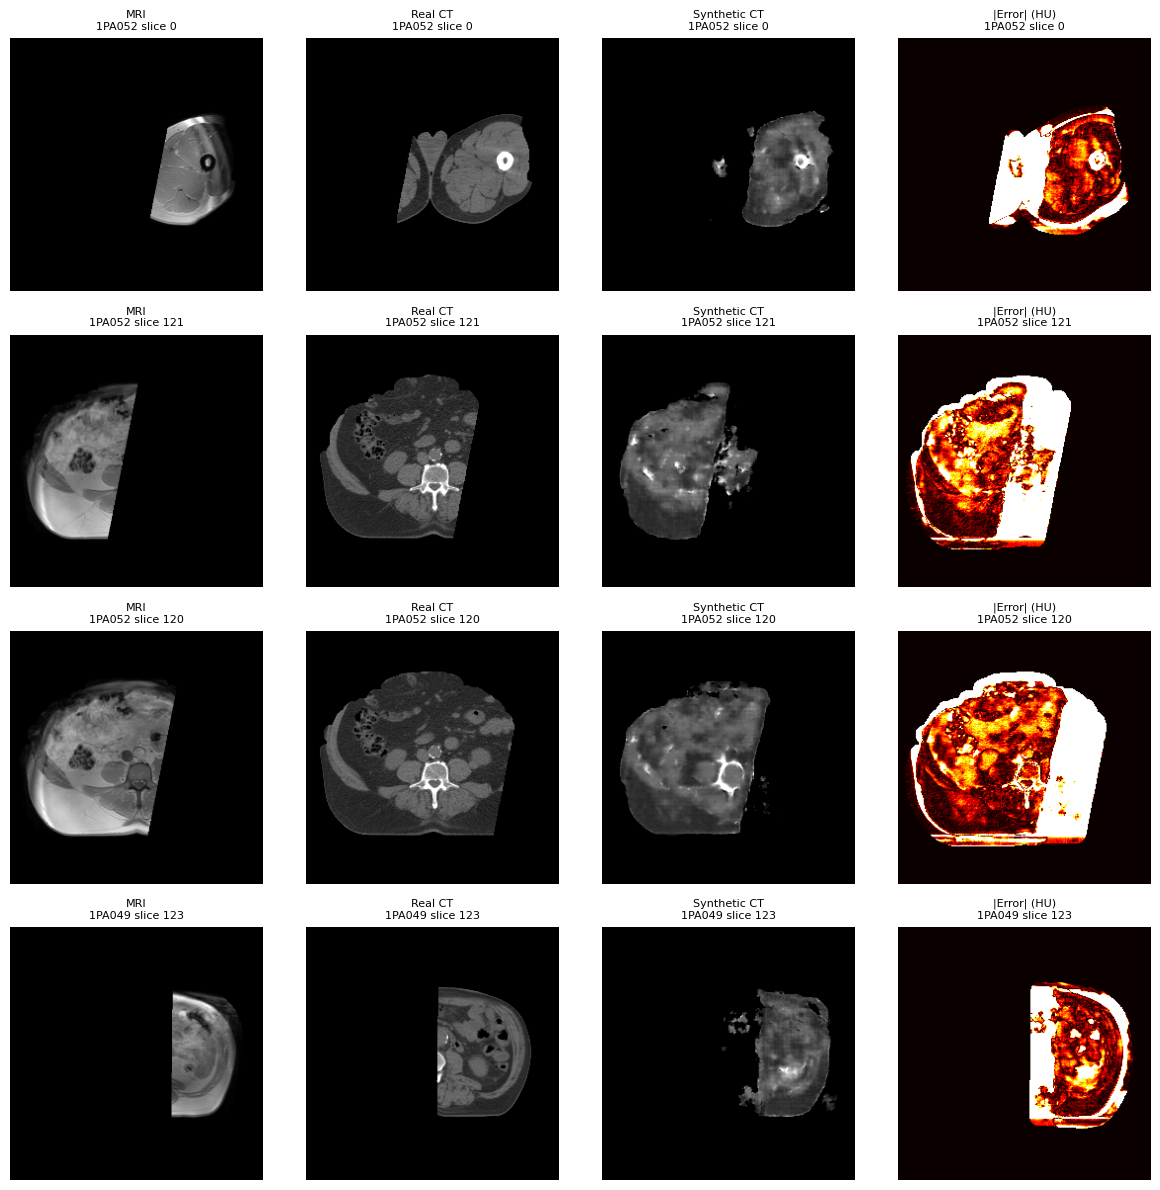

In [16]:
def show_panel(pid, i, axes):
    mr, ct, sct, mk = preds[pid]
    items = [(mr[i], 'MRI', {}),
             (np.clip(ct[i], -200, 400), 'Real CT', {}),
             (np.clip(sct[i], -200, 400), 'Synthetic CT', {}),
             (np.abs(sct[i] - ct[i]) * mk[i], '|Error| (HU)', dict(vmin=0, vmax=200))]
    for a, (im, t, kw) in zip(axes, items):
        a.imshow(im, cmap='hot' if 'Error' in t else 'gray', **kw)
        a.set_title(f'{t}\n{pid} slice {i}', fontsize=8); a.axis('off')

# typical results: middle slice from one Center A, one Center C, and one more test patient
show_ids = [next(p for p in split['test'] if p[2] == 'A'),
            next(p for p in split['test'] if p[2] == 'C'),
            split['test'][-1]]
fig, axs = plt.subplots(len(show_ids), 4, figsize=(12, 3 * len(show_ids)))
for r, pid in enumerate(show_ids):
    show_panel(pid, len(preds[pid][0]) // 2, axs[r])
plt.tight_layout(); plt.savefig(f'{FIG}/qualitative_panel.png', dpi=150); plt.show()

# worst 4 slices = failure cases
worst = sorted(slice_records, key=lambda t: -t[2])[:4]
fig, axs = plt.subplots(4, 4, figsize=(12, 12))
for r, (pid, i, e) in enumerate(worst):
    show_panel(pid, i, axs[r])
plt.tight_layout(); plt.savefig(f'{FIG}/failure_cases.png', dpi=150); plt.show()

## 11. v1 vs v2
The coverage filter changes **which slices are evaluated**, so three rows are compared: the v1 model on all test slices, the v1 model on the filtered slices, and the v2 model on the filtered slices. Filtering the evaluation lowers MAE by about 5 HU; training on filtered data gave no measurable gain (the difference is much smaller than the spread between patients).

In [17]:
import pandas as pd
a = pd.read_csv(f'{PROJECT}/test_metrics.csv')       # v1
b = pd.read_csv(f'{PROJECT}/test_metrics_v2.csv')    # v2
rows = []
for name, d in [('v1 (no filter)', a), ('v2 (coverage filter)', b)]:
    rows.append({'run': name,
                 'MAE_HU': f"{d.MAE_HU.mean():.1f} ± {d.MAE_HU.std():.1f}",
                 'PSNR_dB': f"{d.PSNR_dB.mean():.2f} ± {d.PSNR_dB.std():.2f}",
                 'SSIM': f"{d.SSIM.mean():.3f} ± {d.SSIM.std():.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

                 run      MAE_HU      PSNR_dB          SSIM
      v1 (no filter) 91.0 ± 11.6 24.25 ± 0.92 0.832 ± 0.027
v2 (coverage filter) 87.6 ± 10.1 24.44 ± 0.91 0.826 ± 0.027


In [18]:
G1 = UNetGenerator().to(device)
G1.load_state_dict(torch.load(f'{PROJECT}/checkpoints/best.pt', map_location=device)); G1.eval()

@torch.no_grad()
def eval_on(model, data_dir, pids):
    rows = []
    for pid in tqdm(pids, desc='Evaluating'):
        z = np.load(f'{data_dir}/{pid}.npz')
        mr = torch.from_numpy(z['mr'].astype(np.float32))[:, None]
        out = [model(mr[i:i+16].to(device)).float().cpu() for i in range(0, len(mr), 16)]
        sct = to_hu(torch.cat(out)[:, 0].numpy())
        ct = to_hu(z['ct'].astype(np.float32)); mk = z['mask'] > 0
        mae, psnr, ss = [], [], []
        for i in range(len(ct)):
            m = mk[i]
            mae.append(np.abs(sct[i] - ct[i])[m].mean())
            psnr.append(10 * np.log10(RANGE ** 2 / ((sct[i] - ct[i]) ** 2)[m].mean()))
            ss.append(ssim(ct[i], np.where(m, sct[i], HU_MIN), data_range=RANGE))
        rows.append((pid, np.mean(mae), np.mean(psnr), np.mean(ss)))
    return pd.DataFrame(rows, columns=['patient', 'MAE_HU', 'PSNR_dB', 'SSIM'])

v1_on_v2 = eval_on(G1, f'{PROJECT}/processed_v2', split['test'])

def fmt(d): return (f"{d.MAE_HU.mean():.1f} ± {d.MAE_HU.std():.1f}",
                    f"{d.PSNR_dB.mean():.2f} ± {d.PSNR_dB.std():.2f}",
                    f"{d.SSIM.mean():.3f} ± {d.SSIM.std():.3f}")
table = pd.DataFrame([
    ('v1 model, v1 test slices (all)',     *fmt(a)),
    ('v1 model, v2 test slices (filtered)', *fmt(v1_on_v2)),
    ('v2 model, v2 test slices (filtered)', *fmt(b)),
], columns=['run', 'MAE_HU', 'PSNR_dB', 'SSIM'])
print(table.to_string(index=False))

Evaluating: 100%|██████████| 12/12 [00:16<00:00,  1.37s/it]

                                run      MAE_HU      PSNR_dB          SSIM
     v1 model, v1 test slices (all) 91.0 ± 11.6 24.25 ± 0.92 0.832 ± 0.027
v1 model, v2 test slices (filtered)  85.7 ± 9.6 24.47 ± 0.92 0.830 ± 0.027
v2 model, v2 test slices (filtered) 87.6 ± 10.1 24.44 ± 0.91 0.826 ± 0.027


## 12. How much error comes from partial MRI coverage? (extra analysis)
Several of the worst slices have an MRI that covers only part of the body, while the CT covers all of it, so the model is scored on regions it never saw. This cell re-scores the trained model on slices with more complete MRI coverage and inside the MRI-covered area only.

In [26]:
from scipy import ndimage as ndi
SIG = -0.94      # normalized MRI value above which a pixel counts as having signal
def cover(mr_i, m_i): return (mr_i[m_i] > SIG).mean()
def valid_region(mr_i, m_i):
    return ndi.binary_fill_holes(ndi.binary_closing(mr_i > SIG, iterations=3)) & m_i

rows = []
for t in [0.5, 0.8, 0.9, 0.95]:
    per_pat, n_sl = [], 0
    for pid, (mr, ct, sct, mk) in preds.items():
        e = [np.abs(sct[i] - ct[i])[mk[i]].mean() for i in range(len(ct)) if cover(mr[i], mk[i]) >= t]
        if e: per_pat.append(np.mean(e)); n_sl += len(e)
    rows.append((f'slices with coverage >= {t}', n_sl, f'{np.mean(per_pat):.1f} ± {np.std(per_pat, ddof=1):.1f}'))
per_pat = []
for pid, (mr, ct, sct, mk) in preds.items():
    e = []
    for i in range(len(ct)):
        v = valid_region(mr[i], mk[i])
        if v.sum() > 500: e.append(np.abs(sct[i] - ct[i])[v].mean())
    per_pat.append(np.mean(e))
rows.append(('all slices, inside MRI-covered area only', sum(len(p[1]) for p in preds.values()),
             f'{np.mean(per_pat):.1f} ± {np.std(per_pat, ddof=1):.1f}'))
print(pd.DataFrame(rows, columns=['test subset', 'n slices', 'MAE_HU (mean ± std over patients)']).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:219: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:184: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:219: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcoun

                             test subset  n slices MAE_HU (mean ± std over patients)
             slices with coverage >= 0.5      1236                       87.6 ± 10.1
             slices with coverage >= 0.8       501                       87.8 ± 12.9
             slices with coverage >= 0.9         3                       100.7 ± nan
            slices with coverage >= 0.95         0                         nan ± nan
all slices, inside MRI-covered area only      1236                        76.3 ± 9.6
